# Social Media Mining
## Week 5: Social Media Text Preprocessing & Representation

[nltk_data] Downloading package reuters to /root/nltk_data...
[nltk_data]   Package reuters is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


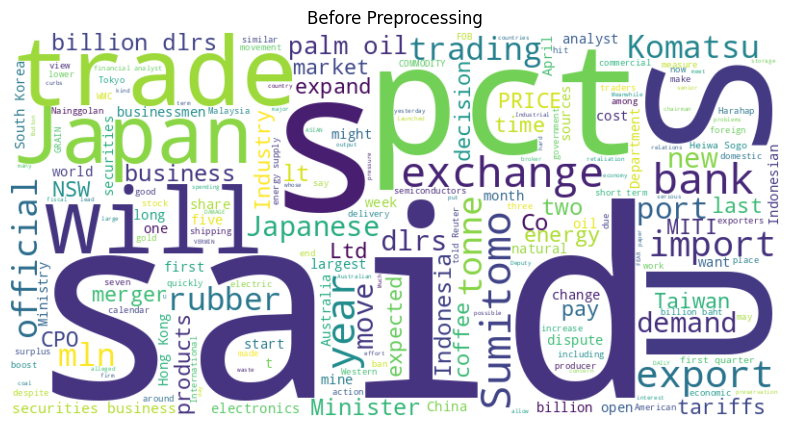


Top Words Before Preprocessing
 Word  Frequency
 the        132
  to         85
  of         83
  in         72
 and         65
said         65
   s         59
   a         57
   u         25
 pct         24


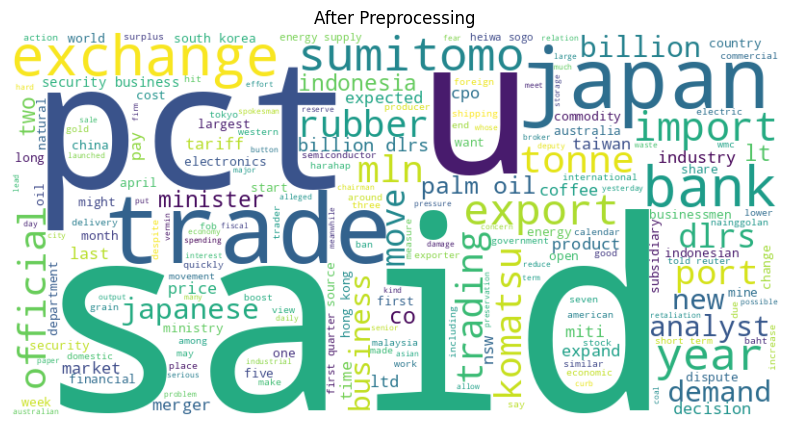


Top Words After Preprocessing
     Word  Frequency
    said         65
       u         27
     pct         24
   trade         23
   japan         17
exchange         16
    bank         16
sumitomo         15
    year         14
    dlrs         13


In [2]:
import nltk
from nltk.corpus import reuters, stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
import string
from wordcloud import WordCloud
import matplotlib.pyplot as plt
from collections import Counter
import pandas as pd

# Ensure datasets are downloaded
nltk.download('reuters')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')

# Retrieve text from the Reuters dataset
documents = reuters.fileids()
text = " ".join(reuters.words(documents[:10]))  # Using the first 10 documents

# Function to display a word cloud
def show_wordcloud(text, title="Word Cloud"):
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(text)
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis("off")
    plt.title(title)
    plt.show()

# Function to display word frequencies in a table
def show_top_words(text, title="Word Frequency"):
    tokens = word_tokenize(text.lower())
    tokens = [word for word in tokens if word.isalnum()]
    word_counts = Counter(tokens)
    df = pd.DataFrame(word_counts.most_common(10), columns=["Word", "Frequency"])
    print(f"\n{title}\n", df.to_string(index=False))

# Word Cloud before preprocessing
show_wordcloud(text, title="Before Preprocessing")
show_top_words(text, title="Top Words Before Preprocessing")

# Text Preprocessing
def preprocess_text(text):
    tokens = word_tokenize(text.lower())  # Tokenization and case folding
    tokens = [word for word in tokens if word.isalnum()]  # Remove punctuation
    tokens = [word for word in tokens if word not in stopwords.words('english')]  # Remove stopwords
    lemmatizer = WordNetLemmatizer()
    tokens = [lemmatizer.lemmatize(word) for word in tokens]  # Lemmatization
    clean_text = " ".join(tokens)
    return clean_text

# Run the preprocessing step
clean_text = preprocess_text(text)

# Ensure the cleaned data is not empty and contains the expected words
if clean_text.strip():
    show_wordcloud(clean_text, title="After Preprocessing")
    show_top_words(clean_text, title="Top Words After Preprocessing")
else:
    print("Cleaned text is empty after preprocessing.")